# Building an ordered hierarchy from asset distances

Correlation is converted into a distance so that strongly positively related assets are close:

$$
d_{ij}=\sqrt{\frac{1-\rho_{ij}}{2}},
\qquad 0\leq d_{ij}\leq1.
$$

Here, $d_{ij}$ is the distance between assets $i$ and $j$, $\rho_{ij}$ is their correlation, and the bounds follow when the correlation lies between minus one and one.

,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Return type,Daily value-weighted return
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Selected industries,16
7,File SHA256,8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71...


,Asset 1,Asset 2,Correlation,Distance
0,Food,Beer,0.806419,0.311112
1,Soda,Beer,0.787213,0.326180
2,Beer,Hshld,0.776844,0.334033
3,Food,Hshld,0.760632,0.345954
4,Hlth,MedEq,0.751082,0.352788
5,Books,Chems,0.730735,0.366923
6,Soda,Hshld,0.728639,0.368348
7,Food,Soda,0.724260,0.371308
8,Chems,Rubbr,0.723364,0.371911
9,Chems,Txtls,0.719779,0.374313


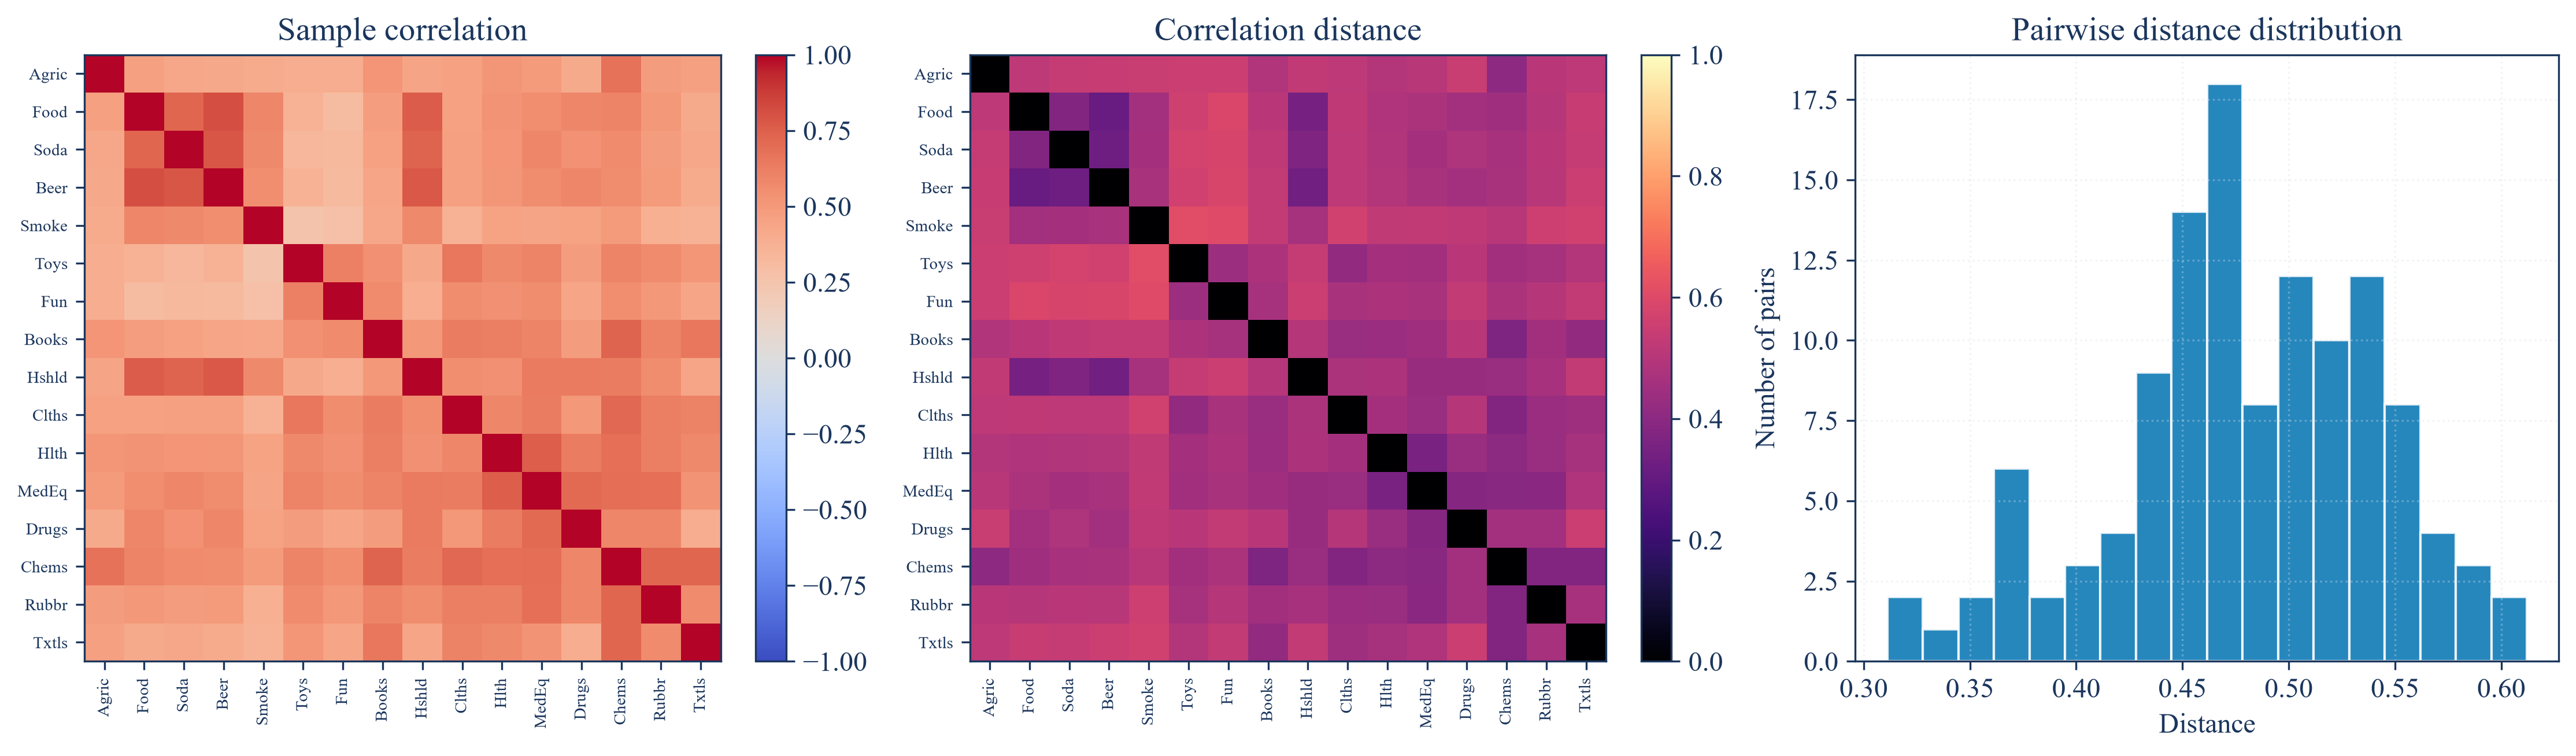

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.optimization.hrp import cluster_variance, distance_corr, hrp, inverse_variance_weights, quasi_diagonal, recursive_bisection

FIGURES = ROOT / "outputs" / "figures" / "25_hierarchical_risk_parity"
TABLES = ROOT / "outputs" / "tables" / "25_hierarchical_risk_parity"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("nan", "Not available").replace("NaN", "Not available").replace("inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def correlation_from_covariance(covariance):
    values = covariance.to_numpy(dtype=float)
    scales = np.sqrt(np.diag(values))
    correlation = values / np.outer(scales, scales)
    correlation = np.clip((correlation + correlation.T) / 2.0, -1.0, 1.0)
    np.fill_diagonal(correlation, 1.0)
    return pd.DataFrame(correlation, index=covariance.index, columns=covariance.columns)

def hierarchy(correlation, method="single"):
    distance = distance_corr(correlation.to_numpy(dtype=float))
    distance = (distance + distance.T) / 2.0
    np.fill_diagonal(distance, 0.0)
    condensed = squareform(distance, checks=True)
    tree = linkage(condensed, method=method)
    order = correlation.index[quasi_diagonal(tree)].tolist()
    return distance, condensed, tree, order

def weights_for_method(covariance, correlation, method="single"):
    _, _, tree, order = hierarchy(correlation, method)
    return recursive_bisection(covariance, order).sort_index(), order, tree

def global_minimum_variance(covariance):
    values = covariance.to_numpy(dtype=float)
    direction = np.linalg.solve(values, np.ones(values.shape[0]))
    weights = direction / direction.sum()
    return pd.Series(weights, index=covariance.index)

def inverse_variance_series(covariance):
    return pd.Series(inverse_variance_weights(covariance), index=covariance.index)

def portfolio_metrics(name, weights, covariance):
    aligned = weights.reindex(covariance.index).to_numpy(dtype=float)
    variance = float(aligned @ covariance.to_numpy(dtype=float) @ aligned)
    concentration = float(aligned @ aligned)
    return {"Portfolio": name, "Annual volatility": float(np.sqrt(variance)), "Largest weight": float(aligned.max()), "Smallest weight": float(aligned.min()), "Gross exposure": float(np.abs(aligned).sum()), "Weight concentration": concentration, "Effective holdings": float(1.0 / concentration)}

def one_way_turnover(current, previous):
    return float(0.5 * np.abs(current.sort_index().to_numpy() - previous.sort_index().to_numpy()).sum())

selected_assets = list(industry_returns.columns[:16])
public_sample = industry_returns[selected_assets].copy()
annual_covariance = public_sample.cov() * 252.0
public_correlation = public_sample.corr()
data_provenance = pd.DataFrame({"Field": ["Archive", "Provider", "Return type", "Analysis start", "Analysis end", "Complete dates", "Selected industries", "File SHA256"], "Value": ["49_Industry_Portfolios_daily_CSV.zip", "Kenneth R. French Data Library", "Daily value-weighted return", str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), len(selected_assets), data_hash]})

save_table(data_provenance, "distance_data_provenance", "Public data used for the Chapter 21 hierarchy study.", "tab:chapter21-distance-data")
display(data_provenance)
distance_values = distance_corr(public_correlation.to_numpy(dtype=float))
distance_values = (distance_values + distance_values.T) / 2.0
np.fill_diagonal(distance_values, 0.0)
condensed_distance = squareform(distance_values, checks=True)
pair_rows = []
for left in range(len(selected_assets)):
    for right in range(left + 1, len(selected_assets)):
        pair_rows.append({"Asset 1": selected_assets[left], "Asset 2": selected_assets[right], "Correlation": public_correlation.iloc[left, right], "Distance": distance_values[left, right]})
closest_pairs = pd.DataFrame(pair_rows).sort_values("Distance").head(12).reset_index(drop=True)
save_table(closest_pairs, "closest_distance_pairs", "Closest public industry pairs under correlation distance.", "tab:chapter21-closest-pairs")
display(closest_pairs)

figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
images = [public_correlation.to_numpy(), distance_values]
titles = ["Sample correlation", "Correlation distance"]
limits = [(-1.0, 1.0), (0.0, 1.0)]
cmaps = ["coolwarm", "magma"]
for axis, matrix, title, bounds, cmap in zip(axes[:2], images, titles, limits, cmaps):
    image = axis.imshow(matrix, vmin=bounds[0], vmax=bounds[1], cmap=cmap, aspect="auto")
    axis.set_title(title)
    axis.set_xticks(range(len(selected_assets)))
    axis.set_yticks(range(len(selected_assets)))
    axis.set_xticklabels(selected_assets, rotation=90, fontsize=7)
    axis.set_yticklabels(selected_assets, fontsize=7)
    figure.colorbar(image, ax=axis, fraction=0.046)
axes[2].hist(condensed_distance, bins=18, color=palette["cyan"], alpha=0.85, edgecolor=palette["background"])
axes[2].set_title("Pairwise distance distribution")
axes[2].set_xlabel("Distance")
axes[2].set_ylabel("Number of pairs")
axes[2].grid(alpha=0.35)
figure.tight_layout()
save_figure(figure, "correlation_distance_matrices")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Linkage Rules

A linkage rule turns distances between individual assets into a distance between two clusters:

$$
D_{\min}(A,B)=\min_{i\in A,\,j\in B}d_{ij},
\qquad
D_{\max}(A,B)=\max_{i\in A,\,j\in B}d_{ij},
\qquad
D_{\mathrm{avg}}(A,B)=\frac{1}{|A||B|}\sum_{i\in A}\sum_{j\in B}d_{ij}.
$$

Here, $A$ and $B$ are two clusters, $i$ and $j$ label assets, $d_{ij}$ is their correlation distance, $D_{\min}$ is single linkage, $D_{\max}$ is complete linkage, $D_{\mathrm{avg}}$ is average linkage, and $|A|$ and $|B|$ are cluster sizes.

,Linkage,Cophenetic correlation,First merge height,Final merge height,Adjacent path length,Mean adjacent correlation
0,Single,0.737289,0.311112,0.454420,6.806020,0.573482
1,Complete,0.732651,0.311112,0.612073,6.264773,0.643193
2,Average,0.779075,0.311112,0.516116,6.449092,0.620755


,Linkage,Position,Industry
0,Single,1,Smoke
1,Single,2,Fun
2,Single,3,Hshld
3,Single,4,Soda
4,Single,5,Food
5,Single,6,Beer
6,Single,7,Toys
7,Single,8,Agric
8,Single,9,Clths
9,Single,10,Txtls


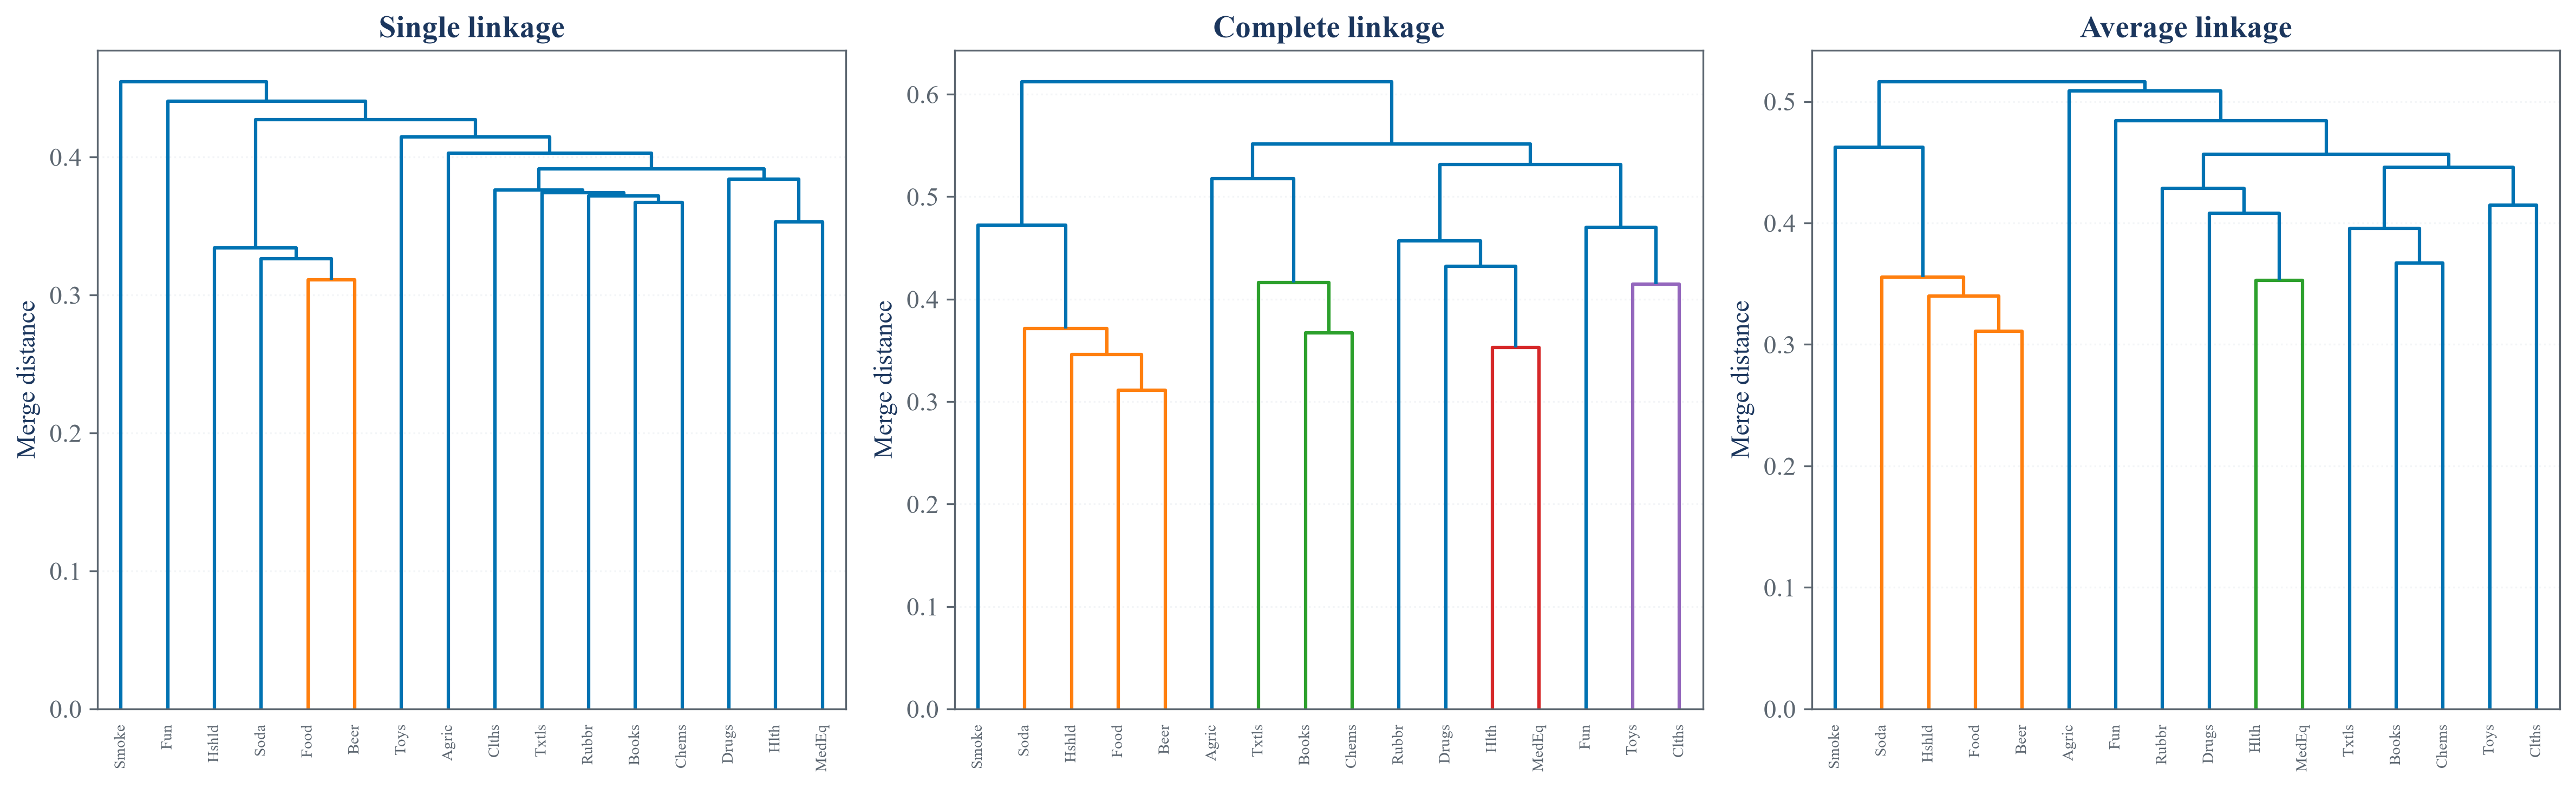

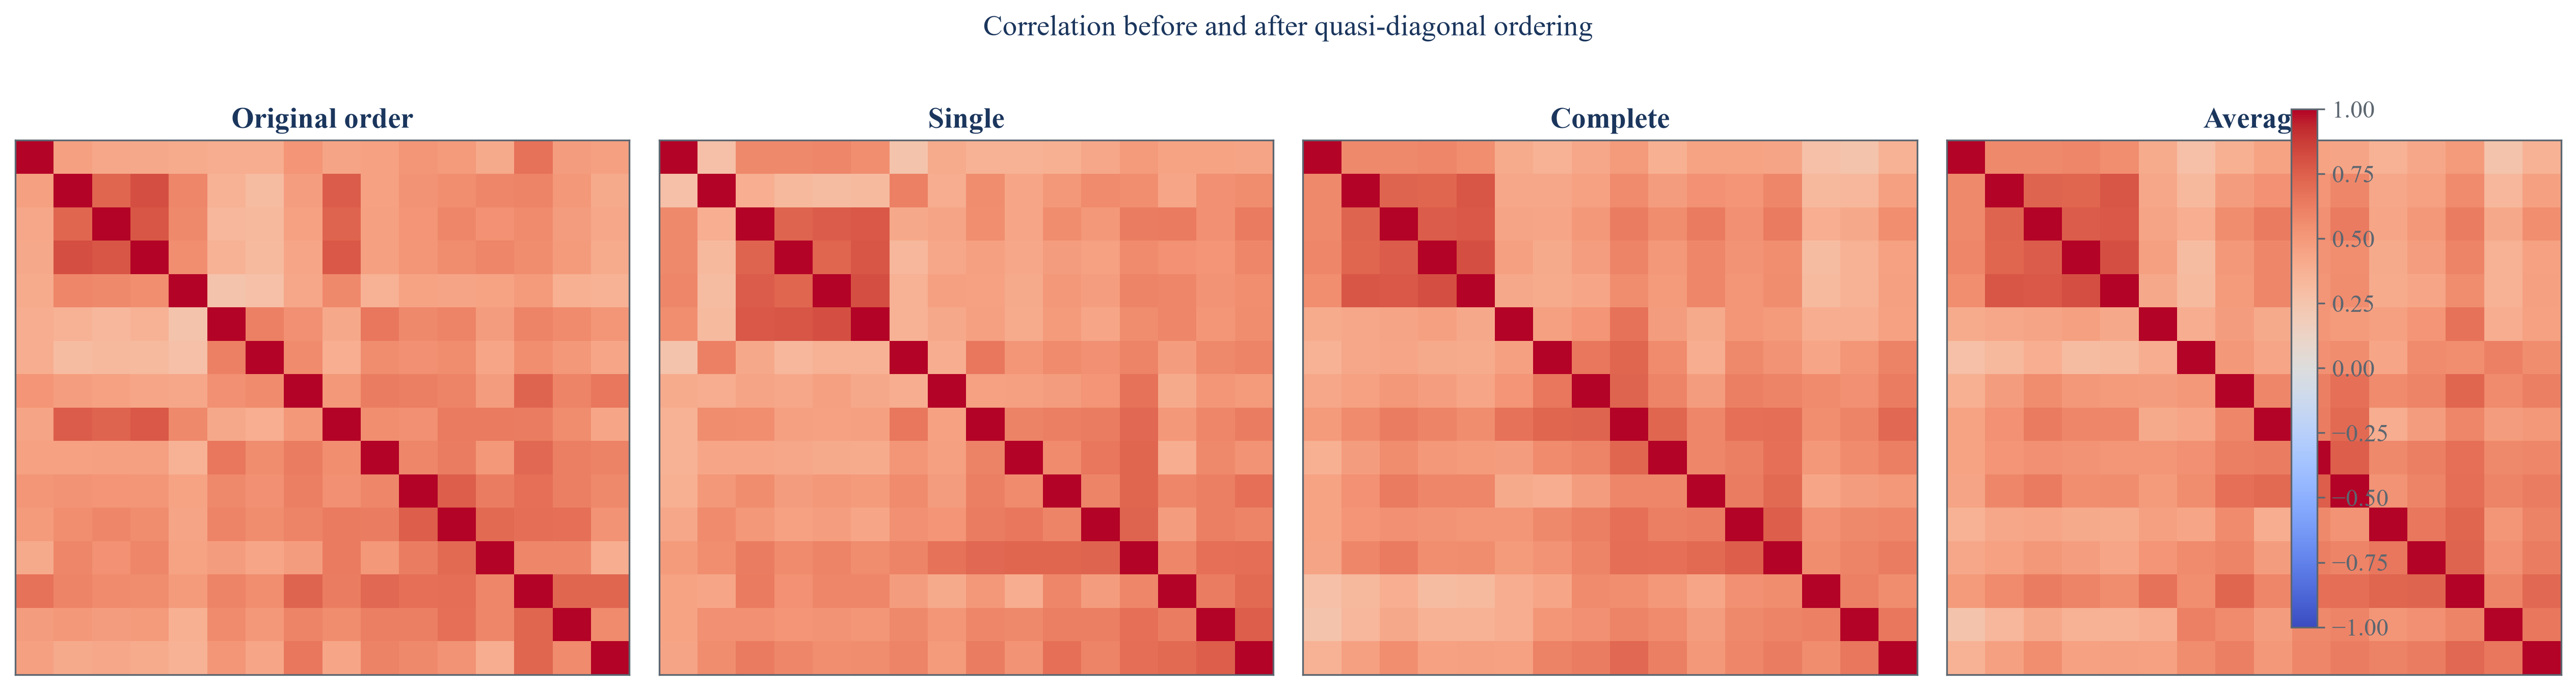

In [2]:
linkage_methods = ["single", "complete", "average"]
hierarchy_results = {}
linkage_rows = []
order_rows = []
for method in linkage_methods:
    distance, condensed, tree, order = hierarchy(public_correlation, method)
    cophenetic_value = float(cophenet(tree, condensed)[0])
    path_length = float(sum(distance[selected_assets.index(order[position]), selected_assets.index(order[position + 1])] for position in range(len(order) - 1)))
    neighbor_correlation = float(np.mean([public_correlation.loc[order[position], order[position + 1]] for position in range(len(order) - 1)]))
    hierarchy_results[method] = {"distance": distance, "condensed": condensed, "tree": tree, "order": order}
    linkage_rows.append({"Linkage": method.title(), "Cophenetic correlation": cophenetic_value, "First merge height": tree[0, 2], "Final merge height": tree[-1, 2], "Adjacent path length": path_length, "Mean adjacent correlation": neighbor_correlation})
    for position, asset in enumerate(order, start=1):
        order_rows.append({"Linkage": method.title(), "Position": position, "Industry": asset})
linkage_summary = pd.DataFrame(linkage_rows)
order_comparison = pd.DataFrame(order_rows)
save_table(linkage_summary, "linkage_summary", "Hierarchy summaries for three linkage rules.", "tab:chapter21-linkage-summary")
save_table(order_comparison, "linkage_orders", "Quasi-diagonal industry orders under three linkage rules.", "tab:chapter21-linkage-orders")
display(linkage_summary)
display(order_comparison)

figure, axes = plt.subplots(1, 3, figsize=(16, 5))
for axis, method in zip(axes, linkage_methods):
    dendrogram(hierarchy_results[method]["tree"], labels=selected_assets, leaf_rotation=90, leaf_font_size=7, color_threshold=None, above_threshold_color=palette["cyan"], ax=axis)
    axis.set_title(f"{method.title()} linkage")
    axis.set_ylabel("Merge distance")
    axis.grid(axis="y", alpha=0.3)
figure.tight_layout()
save_figure(figure, "linkage_dendrograms")

figure, axes = plt.subplots(1, 4, figsize=(17, 4.4))
base_image = axes[0].imshow(public_correlation.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
axes[0].set_title("Original order")
axes[0].set_xticks([])
axes[0].set_yticks([])
for axis, method in zip(axes[1:], linkage_methods):
    order = hierarchy_results[method]["order"]
    ordered = public_correlation.loc[order, order]
    axis.imshow(ordered.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
    axis.set_title(method.title())
    axis.set_xticks([])
    axis.set_yticks([])
figure.colorbar(base_image, ax=axes, fraction=0.018, pad=0.02)
figure.suptitle("Correlation before and after quasi-diagonal ordering", y=1.02)
figure.tight_layout()
save_figure(figure, "ordered_correlation_comparison")

## Ordering Diagnostics

One useful diagnostic adds the distances between neighbors in an ordered asset list:

$$
L(\pi)=\sum_{k=1}^{N-1}d_{\pi_k,\pi_{k+1}}.
$$

Here, $\pi=(\pi_1,\ldots,\pi_N)$ is an asset ordering, $N$ is the number of assets, $d_{\pi_k,\pi_{k+1}}$ is the distance between adjacent ordered assets, and $L(\pi)$ is an adjacency diagnostic rather than the rule used to fit the hierarchy.

,Linkage,Mean prior-window agreement,Minimum prior-window agreement,Mean path length,Mean cophenetic correlation
0,Average,0.644661,-0.015561,6.466993,0.843831
1,Complete,0.597515,-0.015561,6.415828,0.798060
2,Single,0.422813,0.027113,6.547280,0.793616


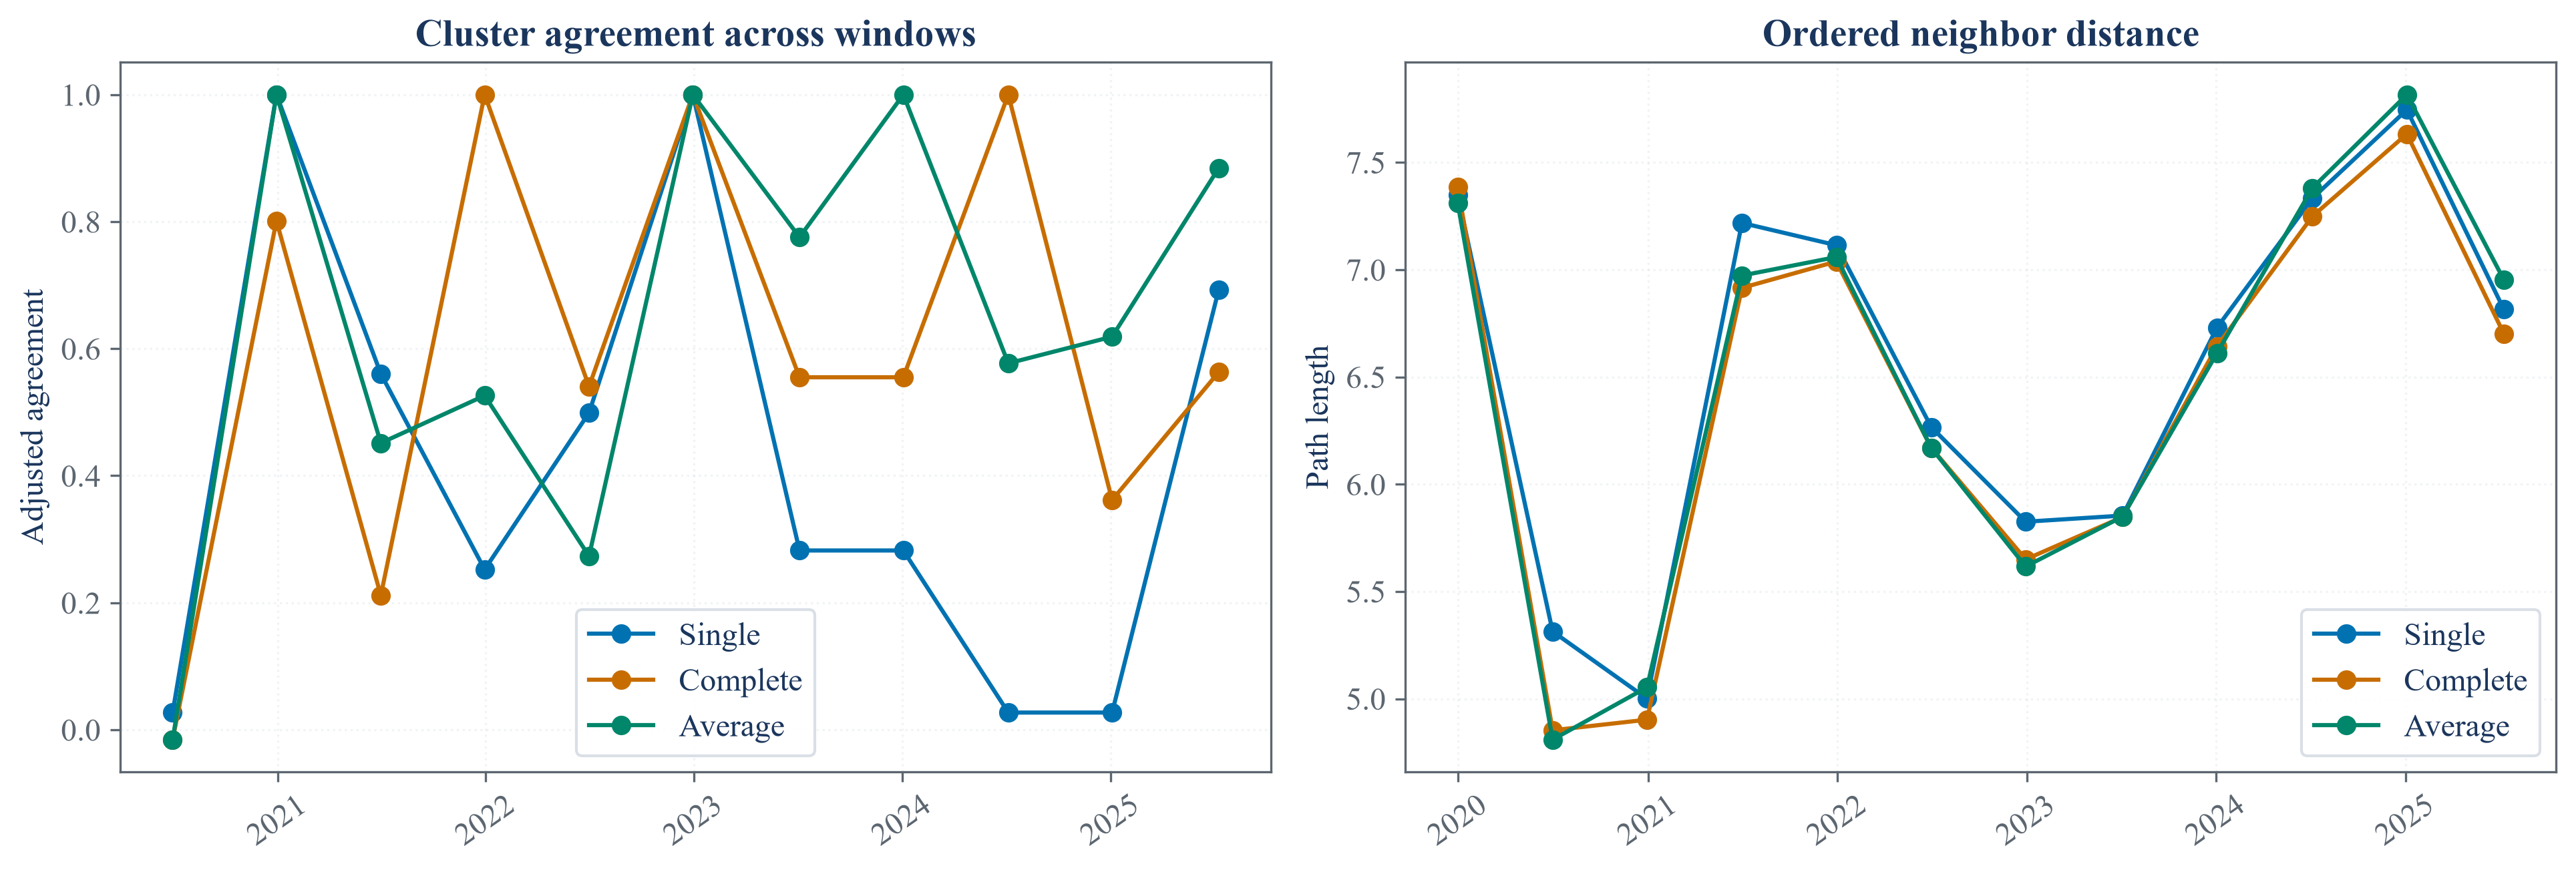

,Quantity,Value
0,Assets,16
1,Public observations,1760
2,Pairwise distances,120
3,Linkage rules,3
4,Rolling windows,12
5,Smallest observed distance,0.311112
6,Largest observed distance,0.612073


In [3]:
rolling_rows = []
previous_labels = {method: None for method in linkage_methods}
endpoint_positions = list(range(251, len(public_sample), 126))
for endpoint in endpoint_positions:
    window = public_sample.iloc[endpoint - 251:endpoint + 1]
    correlation = window.corr()
    for method in linkage_methods:
        distance, condensed, tree, order = hierarchy(correlation, method)
        labels = fcluster(tree, t=4, criterion="maxclust")
        agreement = np.nan if previous_labels[method] is None else adjusted_rand_score(previous_labels[method], labels)
        rolling_rows.append({"Window end": str(window.index[-1].date()), "Linkage": method.title(), "Observations": len(window), "Four-cluster agreement with prior window": agreement, "Adjacent path length": float(sum(distance[selected_assets.index(order[position]), selected_assets.index(order[position + 1])] for position in range(len(order) - 1))), "Cophenetic correlation": float(cophenet(tree, condensed)[0])})
        previous_labels[method] = labels
rolling_tree_stability = pd.DataFrame(rolling_rows)
tree_stability_summary = rolling_tree_stability.groupby("Linkage", as_index=False).agg(**{"Mean prior-window agreement": ("Four-cluster agreement with prior window", "mean"), "Minimum prior-window agreement": ("Four-cluster agreement with prior window", "min"), "Mean path length": ("Adjacent path length", "mean"), "Mean cophenetic correlation": ("Cophenetic correlation", "mean")})
save_table(rolling_tree_stability, "rolling_tree_stability", "Rolling public hierarchy diagnostics.", "tab:chapter21-rolling-tree-stability")
save_table(tree_stability_summary, "tree_stability_summary", "Summary of rolling public hierarchy diagnostics.", "tab:chapter21-tree-stability-summary")
display(tree_stability_summary)

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method, color in zip([name.title() for name in linkage_methods], [palette["cyan"], palette["amber"], palette["green"]]):
    subset = rolling_tree_stability[rolling_tree_stability["Linkage"] == method]
    axes[0].plot(pd.to_datetime(subset["Window end"]), subset["Four-cluster agreement with prior window"], marker="o", label=method, color=color)
    axes[1].plot(pd.to_datetime(subset["Window end"]), subset["Adjacent path length"], marker="o", label=method, color=color)
axes[0].set_title("Cluster agreement across windows")
axes[0].set_ylabel("Adjusted agreement")
axes[1].set_title("Ordered neighbor distance")
axes[1].set_ylabel("Path length")
for axis in axes:
    axis.grid(alpha=0.35)
    axis.legend()
    axis.tick_params(axis="x", rotation=35)
figure.tight_layout()
save_figure(figure, "window_tree_stability")

section_summary = pd.DataFrame({"Quantity": ["Assets", "Public observations", "Pairwise distances", "Linkage rules", "Rolling windows", "Smallest observed distance", "Largest observed distance"], "Value": [len(selected_assets), len(public_sample), len(condensed_distance), len(linkage_methods), len(endpoint_positions), condensed_distance.min(), condensed_distance.max()]})
save_table(section_summary, "distance_section_summary", "Section 21.1 numerical summary.", "tab:chapter21-distance-summary")
display(section_summary)

## Tests

In [4]:
assert data_hash == EXPECTED_DATA_HASH
assert public_sample.shape == (1760, 16)
assert np.allclose(distance_values, distance_values.T)
assert np.allclose(np.diag(distance_values), 0.0)
assert distance_values.min() >= 0.0
assert distance_values.max() <= 1.0
assert len(condensed_distance) == len(selected_assets) * (len(selected_assets) - 1) // 2
assert np.allclose(squareform(condensed_distance), distance_values)
assert closest_pairs["Distance"].is_monotonic_increasing
assert len(hierarchy_results) == 3
assert all(sorted(result["order"]) == sorted(selected_assets) for result in hierarchy_results.values())
assert all(result["tree"].shape == (len(selected_assets) - 1, 4) for result in hierarchy_results.values())
assert linkage_summary["Cophenetic correlation"].between(0.0, 1.0).all()
assert linkage_summary["Final merge height"].gt(linkage_summary["First merge height"]).all()
assert order_comparison.groupby("Linkage")["Industry"].nunique().eq(len(selected_assets)).all()
assert rolling_tree_stability["Observations"].eq(252).all()
assert rolling_tree_stability["Four-cluster agreement with prior window"].dropna().between(-1.0, 1.0).all()
assert len(tree_stability_summary) == 3
assert (FIGURES / "correlation_distance_matrices.pdf").is_file()
assert (FIGURES / "linkage_dendrograms.pdf").is_file()
assert (FIGURES / "ordered_correlation_comparison.pdf").is_file()
assert (FIGURES / "window_tree_stability.pdf").is_file()
assert (TABLES / "linkage_summary.tex").is_file()
assert (TABLES / "rolling_tree_stability.tex").is_file()